In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn as sk
from sklearn.impute import SimpleImputer

In [10]:
url = "https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv"

df = pd.read_csv(url)

In [11]:
df.head(5)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [12]:
df.shape

(768, 9)

In [13]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [15]:
(df == 0).sum()

Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64



Lors de l'EDA, on voit que certaines colonnes contiennent des valeurs à 0 qui ne sont pas médicalement plausibles.

Nous avons donc remplacé ces zéros par des `NaN` pour les identifier comme valeurs manquantes.

Ensuite, nous séparons les données en ensembles d'entraînement et de test.

Nous utilisons `SimpleImputer` pour remplacer les `NaN` par la médiane de chaque colonne. L'imputer est entraîné uniquement sur `X_train`, puis appliqué à `X_train` et `X_test`.

Cela permet d'éviter le **data leakage**, car les données de test ne doivent pas influencer les valeurs utilisées pour préparer le modèle.

In [16]:
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

df[cols] = df[cols].replace(0, np.nan)

In [23]:
X = df.drop(columns=["Outcome"])
Y = df['Outcome']

In [24]:
X_train, X_test, Y_train, Y_test = sk.model_selection.train_test_split(X, Y, test_size=0.2, random_state=42)

In [26]:
Imputer = SimpleImputer(strategy='median')

imputer = Imputer.fit(X_train)

X_train = imputer.transform(X_train)
X_test = imputer.transform(X_test)

Pourquoi ne pas faire fit() sur X_test :
Parce que ca permettrait d'utiliser des informations qui viennet des données de test pour préparer notre modèle. Donc data leakage.
Le modèle doit être évalué sur des données qu'il n'a jamais utilisées pour apprendre.

SimpleImputer est la pour apprendre les médianes, tandis que le fit() et notre futur KNN ou Decision Tree servira à apprendre à prédire le diabète.

Le standard scaler pour knn : hyper important. 
Sinon on standartiste pas le KNN, certaines variables peuvent dominer le calcul des distances à cause de leur échelle.

ex : 

- Glucose : valeurs autour de 70 à 200.
- Age : valeurs autour de 20 à 80.
- DiabetesPedigreeFunction : valeurs souvent entre 0 et 2.

Sans standardisation, une différence de 50 en glucose pèsera beaucoup plus dans la distance qu'une différence de 0,5 dans DiabetesPedigreeFunction.
Avec StandardScaler, chaque variable est transformée pour avoir approximativement :
- Une moyenne de 0.
- Un écart-type de 1.
Ainsi, KNN peut comparer les observations sans qu'une variable domine uniquement à cause de son unité de mesure.

À retenir :
- X_train + y_train = apprendre.
- X_test = faire des prédictions.
- y_test = vérifier si les prédictions sont correctes.

In [27]:
from sklearn.preprocessing import StandardScaler
scaller = StandardScaler()

train_score_scaled = scaller.fit_transform(X_train)
test_score_scaled = scaller.transform(X_test)


On entraine le knn 

In [30]:
from sklearn.neighbors import KNeighborsClassifier

In [37]:


from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(train_score_scaled, Y_train)


KNeighborsClassifier()

In [38]:
train_accuracy = knn.score(train_score_scaled, Y_train)
test_accuracy = knn.score(test_score_scaled, Y_test)

print("Accuracy train :", train_accuracy)
print("Accuracy test :", test_accuracy)

Accuracy train : 0.8192182410423453
Accuracy test : 0.7142857142857143


In [40]:
Y_pred = knn.predict(test_score_scaled)

-knn : le modèle déjà entraîné.
-test_score_scaled : le X_test après standardisation. Ce sont les informations des patients du jeu de test.
-.predict() : demande au KNN de prédire si chaque patient est diabétique.
-Y_pred : stocke les réponses prédites.

**Matrice de Confusion**

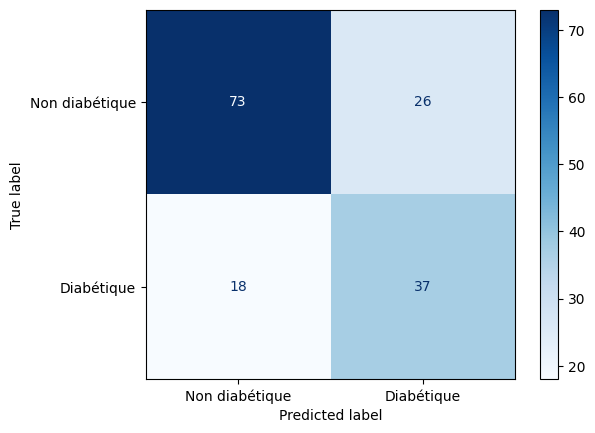

In [41]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(Y_test, Y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non diabétique", "Diabétique"]
)

disp.plot(cmap="Blues")
plt.show()

In [42]:
from sklearn.metrics import recall_score

recall = recall_score(Y_test, Y_pred)

print("Recall :", recall)

Recall : 0.6727272727272727


Ok, le modele est pas ouf : 26 faux positifs et 18 faux négatifs.
Accuracy de 71,43 %, mais recall pour la classe diabétique de 67,27 %.



In [43]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy :", accuracy_score(Y_test, Y_pred))
print("Precision :", precision_score(Y_test, Y_pred))
print("Recall :", recall_score(Y_test, Y_pred))
print("F1-score :", f1_score(Y_test, Y_pred))

Accuracy : 0.7142857142857143
Precision : 0.5873015873015873
Recall : 0.6727272727272727
F1-score : 0.6271186440677966


On va essayer d'améliorer ca en optimisant le KNN 
Go pour une validation croisée pour voir le changement 

In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier

for k in range(1, 21):
    knn = KNeighborsClassifier(n_neighbors=k)

    scores = cross_val_score(
        knn,
        train_score_scaled,
        Y_train,
        cv=5,
        scoring="f1"
    )

    print(k, scores.mean())

1 0.584089039318094
2 0.4874713692104996
3 0.5799146196729417
4 0.5232763525300839
5 0.6065280432883603
6 0.5414841976217041
7 0.6168465608465608
8 0.5815221316752242
9 0.6291356213478593
10 0.586308200423326
11 0.6306203822870489
12 0.5847831197146266
13 0.6226046316552645
14 0.5887987987987988
15 0.6159170276638631
16 0.5955775173919333
17 0.6232920232920233
18 0.6116515349449944
19 0.6291483368951724
20 0.6064111379711703


Le 11 semble mieux prédir que les autres, mtn on fait la matrice de corrélation pour voir quelles variables semblent les plus pertinentes pour prédire le diabète.

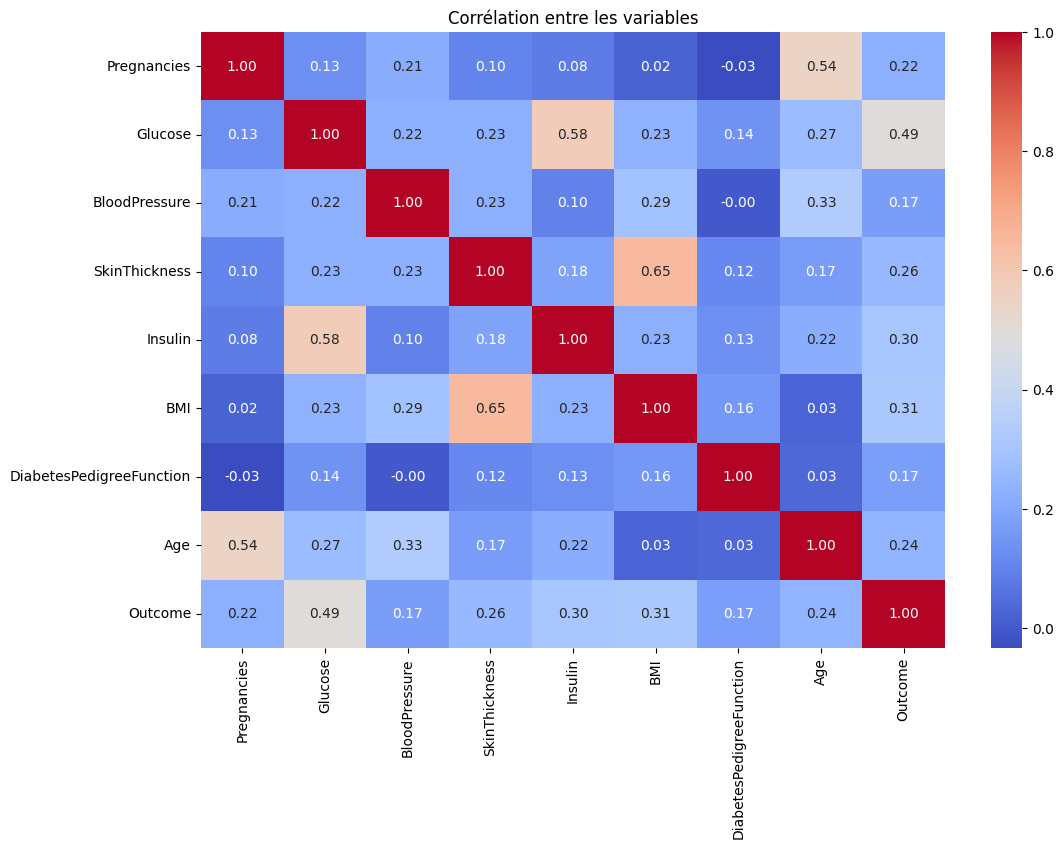

In [46]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Corrélation entre les variables")
plt.show()

Glucose présente la plus forte corrélation avec Outcome : 0,49 (important)

BMI et SkinThickness sont corrélées entre elles : 0,65.

Glucose et Insulin présentent également une corrélation élevée : 0,58.

BloodPressure et DiabetesPedigreeFunction présentent des corrélations plus faibles avec Outcome : 0,17 chacune.



On refait le test avec en virant SkinThickness en repartnat de X car ca a deja été transformé.

In [ ]:
 from sklearn.model_selection import train_test_split

X_train_raw, X_test_raw, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

X_train_all = X_train_raw.copy()

X_train_selected = X_train_raw.drop(columns=["SkinThickness"])

In [48]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_val_score

pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=11)
)

score_all = cross_val_score(
    pipeline, X_train_all, Y_train,
    cv=5, scoring="f1"
)

score_selected = cross_val_score(
    pipeline, X_train_selected, Y_train,
    cv=5, scoring="f1"
)

print("F1 avec 8 features :", score_all.mean())
print("F1 avec 7 features :", score_selected.mean())

F1 avec 8 features : 0.6338082006498185
F1 avec 7 features : 0.6388101019073703


Retirer SkinThickness améliore légèrement le F1-score, de 0,005, soit 0,5 point de pourcentage,
mais la diff est très faible. On peut pas encore affirmer que cette variable est inutile.

Retentons en enlevant BMI

In [49]:
X_train_without_bmi = X_train_raw.drop(columns=["BMI"])

score_without_bmi = cross_val_score(
    pipeline,
    X_train_without_bmi,
    Y_train,
    cv=5,
    scoring="f1"
)

print("F1 sans BMI :", score_without_bmi.mean())

F1 sans BMI : 0.576567783094099


Bon, c'est encore pire sans le BMI, autant le garder 

Mtn on peut retirer chaque variable une par une, en repartant des 8 features initiales, pour mesurer son influence sur le F1-score 

In [50]:
results = []

for col in X_train_raw.columns:
    X_temp = X_train_raw.drop(columns=[col])

    scores = cross_val_score(
        pipeline,
        X_temp,
        Y_train,
        cv=5,
        scoring="f1"
    )

    results.append({
        "Feature supprimée": col,
        "F1-score": scores.mean()
    })

df_results = pd.DataFrame(results)

df_results = df_results.sort_values(
    by="F1-score",
    ascending=False
)

display(df_results)

,Feature supprimée,F1-score
3,SkinThickness,0.638810
6,DiabetesPedigreeFunction,0.620981
0,Pregnancies,0.612746
2,BloodPressure,0.602056
7,Age,0.587230
5,BMI,0.576568
4,Insulin,0.575029
1,Glucose,0.501180


Conclusions : sans glucose le modèle est imprécis (logique)
- Insulin et BMI semblent utiles
- SkinThickness est donc la seule variable dont la suppression améliore (un peu) le score

Mtn on peut verif si K = 11 reste le meilleur choix

In [51]:
results_k = []

for k in range(1, 21):
    pipeline.set_params(
        kneighborsclassifier__n_neighbors=k
    )

    scores = cross_val_score(
        pipeline,
        X_train_selected,
        Y_train,
        cv=5,
        scoring="f1"
    )

    results_k.append({
        "K": k,
        "F1-score": scores.mean()
    })

df_k = pd.DataFrame(results_k)

display(df_k.sort_values("F1-score", ascending=False))

,K,F1-score
14,15,0.661377
16,17,0.648766
18,19,0.647091
8,9,0.643894
10,11,0.638810
12,13,0.632317
15,16,0.629631
17,18,0.629416
19,20,0.628278
6,7,0.628137


OK interessant, sans le SkinThickness le meilleur knn n'est plus  11 mais pas 15, on peut donc essayer le modele final avec ce qu'on a appris 

In [52]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

final_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=15)
)

final_pipeline.fit(X_train_selected, Y_train)

X_test_selected = X_test_raw.drop(columns=["SkinThickness"])

Y_pred = final_pipeline.predict(X_test_selected)

print("Accuracy :", accuracy_score(Y_test, Y_pred))
print("Precision :", precision_score(Y_test, Y_pred))
print("Recall :", recall_score(Y_test, Y_pred))
print("F1-score :", f1_score(Y_test, Y_pred))
print("Matrice de confusion :")
print(confusion_matrix(Y_test, Y_pred))

Accuracy : 0.7467532467532467
Precision : 0.66
Recall : 0.6
F1-score : 0.6285714285714286
Matrice de confusion :
[[82 17]
 [22 33]]


Le modèle final améliore l'accuracy et la précision, mais son rappel diminue. Le F1-score reste quasiment identique.
le premier modele prédisait moins de faux-négatif...donc davantage de vrais diabétiques, mais il déclenche aussi plus de fausses alerte

Celui ci est plus prudent lorsqu'il prédit le diabète, mais il manque davantage de vrais malades.

D'apres les infos que j'ai trouvé, pour le domaine médical, on privilégie le recall, car manquer une personne malade peut avoir des conséquences importantes, donc le 1er modèle l'emporte.
Une meilleur accuracy n'est pas forcément adapté au contexte